# Lab 07 — Improving HOG-Based Medical Image Classification Using a Genetic Algorithm
**Dataset:** PneumoniaMNIST (binary: Normal vs Pneumonia chest X-ray) — Kaggle: `rijulshr/pneumoniamnist`
**Pipeline:** HOG (128×128, 9 orient., 8×8 cells, 2×2 blocks, L2-Hys) → RBF-SVM (baseline) vs. GA feature selection → RBF-SVM (proposed)

## 0. Setup

In [1]:
!pip -q install kagglehub scikit-image opencv-python-headless seaborn

import os, time, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import cv2, torch
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix)
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only (slower!)")

OUT_DIR = "/content/lab07_outputs"; os.makedirs(OUT_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

Device: cpu | CPU only (slower!)


## 1. Dataset (PneumoniaMNIST)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rijulshr/pneumoniamnist")

print("Path to dataset files:", path)
for dp, dn, fn in os.walk(path):
    print(dp, "->", fn[:8], "..." if len(fn) > 8 else "")

100%|██████████| 3.39M/3.39M [00:00<00:00, 93.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rijulshr/pneumoniamnist/versions/1
/root/.cache/kagglehub/datasets/rijulshr/pneumoniamnist/versions/1 -> ['pneumoniamnist.npz'] 


Loaded npz: /root/.cache/kagglehub/datasets/rijulshr/pneumoniamnist/versions/1/pneumoniamnist.npz ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
split  n_images native_shape  Normal  Pneumonia
train      3882     (28, 28)     388       3494
  val       524     (28, 28)     135        389
 test       624     (28, 28)     234        390


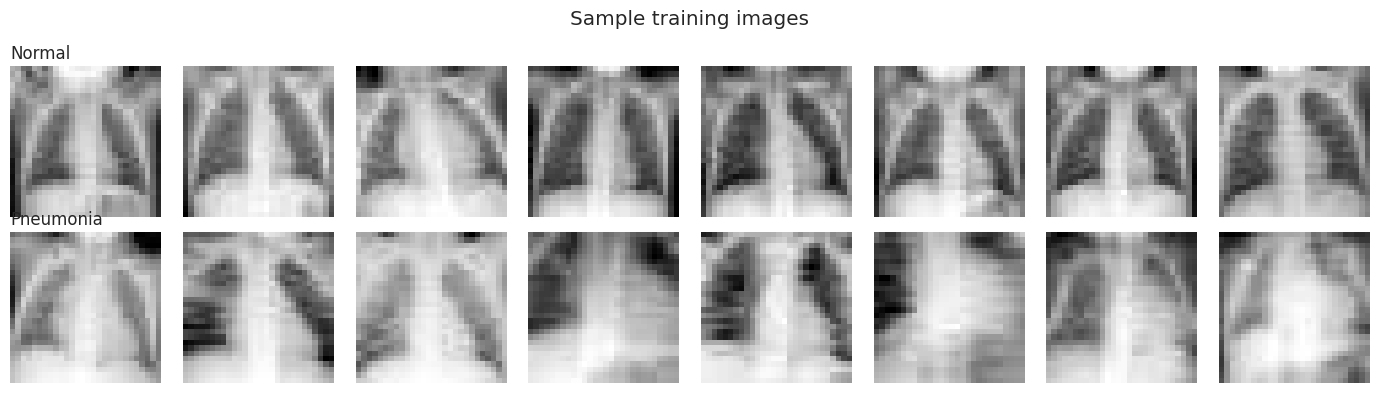

In [3]:
IMG_SIZE = 128

def _to_gray_uint8(arr):
    arr = np.asarray(arr)
    if arr.ndim == 4:                       # (N,H,W,C) or (N,C,H,W)
        arr = arr[..., 0] if arr.shape[-1] in (1, 3) else arr[:, 0]
    if arr.dtype != np.uint8:
        arr = (arr * 255).clip(0, 255).astype(np.uint8) if arr.max() <= 1.0 else arr.astype(np.uint8)
    return arr

def load_dataset(root):
    # (a) MedMNIST-style .npz  (train_images, train_labels, val_images, ...)
    npz = sorted(glob.glob(os.path.join(root, "**", "*.npz"), recursive=True))
    if npz:
        f = next((p for p in npz if "pneumonia" in os.path.basename(p).lower()), npz[0])
        d = np.load(f); print("Loaded npz:", f, list(d.keys()))
        return {s: (_to_gray_uint8(d[f"{s}_images"]), d[f"{s}_labels"].ravel().astype(int)) for s in ["train", "val", "test"]}
    # (b) separate .npy files
    npy = {os.path.basename(p)[:-4]: p for p in glob.glob(os.path.join(root, "**", "*.npy"), recursive=True)}
    if all(f"{s}_images" in npy and f"{s}_labels" in npy for s in ["train", "val", "test"]):
        print("Loaded .npy files")
        return {s: (_to_gray_uint8(np.load(npy[f"{s}_images"])), np.load(npy[f"{s}_labels"]).ravel().astype(int)) for s in ["train", "val", "test"]}
    # (c) image folders  train/ val/ test/  with one sub-folder per class
    alias = {"train": "train", "val": "val", "valid": "val", "validation": "val", "test": "test"}
    split_dirs = {}
    for dp, dn, _ in os.walk(root):
        for d in dn:
            k = alias.get(d.lower())
            if k and k not in split_dirs:
                split_dirs[k] = os.path.join(dp, d)
    if "train" not in split_dirs or "test" not in split_dirs:
        raise RuntimeError(f"Could not recognise dataset layout under {root}. Found: {split_dirs}")
    classes = sorted({c for s in split_dirs.values() for c in os.listdir(s) if os.path.isdir(os.path.join(s, c))})
    print("Loaded image folders, classes:", classes)
    out = {}
    for s, sd in split_dirs.items():
        X, y = [], []
        for ci, c in enumerate(classes):
            for p in glob.glob(os.path.join(sd, c, "*")):
                im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
                if im is not None:
                    X.append(cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)); y.append(ci)
        out[s] = (np.array(X, dtype=np.uint8), np.array(y))
    return out

data = load_dataset(path)
if "val" not in data:   # create a validation split from train if the dataset has none
    Xtr, Xva, ytr, yva = train_test_split(*data["train"], test_size=0.15, stratify=data["train"][1], random_state=SEED)
    data["train"], data["val"] = (Xtr, ytr), (Xva, yva)

CLASS_NAMES = ["Normal", "Pneumonia"] if len(np.unique(data["train"][1])) == 2 else [f"class_{i}" for i in np.unique(data["train"][1])]
rows = []
for s in ["train", "val", "test"]:
    X, y = data[s]
    rows.append({"split": s, "n_images": len(y), "native_shape": X.shape[1:], **{CLASS_NAMES[c]: int((y == c).sum()) for c in range(len(CLASS_NAMES))}})
print(pd.DataFrame(rows).to_string(index=False))

fig, axs = plt.subplots(len(CLASS_NAMES), 8, figsize=(14, 2 * len(CLASS_NAMES)))
Xt, yt = data["train"]
for c in range(len(CLASS_NAMES)):
    ids = np.where(yt == c)[0][:8]
    for j, i in enumerate(ids):
        axs[c, j].imshow(Xt[i], cmap="gray"); axs[c, j].axis("off")
    axs[c, 0].set_title(CLASS_NAMES[c], loc="left")
plt.suptitle("Sample training images"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/samples.png", dpi=150); plt.show()

## 2. Preprocessing + HOG feature extraction (identical for both pipelines)

In [4]:
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)

def prep_hog(img):
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC).astype(np.float32) / 255.0
    return hog(img, **HOG_PARAMS).astype(np.float32)

def extract_hog(X):
    return np.stack(Parallel(n_jobs=-1, batch_size=64)(delayed(prep_hog)(x) for x in X))

t0 = time.time()
F, Y = {}, {}
for s in ["train", "val", "test"]:
    F[s] = extract_hog(data[s][0]); Y[s] = data[s][1]
    print(f"{s:5s}: {F[s].shape}")
T_HOG = time.time() - t0
N_FEAT = F["train"].shape[1]
print(f"\nHOG feature dimension = {N_FEAT}  |  extraction time = {T_HOG:.1f}s")

# move features to GPU once
G = {s: torch.as_tensor(F[s], dtype=torch.float32, device=DEVICE) for s in F}
ALL_IDX = torch.arange(N_FEAT, device=DEVICE)

train: (3882, 8100)
val  : (524, 8100)
test : (624, 8100)

HOG feature dimension = 8100  |  extraction time = 58.5s


## 3. Table 1 — Experimental configuration

In [5]:
t1 = pd.DataFrame([
    ["Medical dataset", "PneumoniaMNIST", "PneumoniaMNIST"],
    ["Image resolution", f"{IMG_SIZE} × {IMG_SIZE}", f"{IMG_SIZE} × {IMG_SIZE}"],
    ["HOG orientations", 9, 9],
    ["Pixels per cell", "8 × 8", "8 × 8"],
    ["Cells per block", "2 × 2", "2 × 2"],
    ["Block normalization", "L2-Hys", "L2-Hys"],
    ["HOG feature dimension", N_FEAT, N_FEAT],
    ["Feature selection", "None", "Genetic Algorithm (binary mask)"],
    ["Classifier", "SVM", "SVM"],
    ["SVM kernel", "RBF (GPU-computed, precomputed)", "RBF (GPU-computed, precomputed)"],
    ["Class weights", "balanced", "balanced"],
    ["Hyperparameter tuning", "Validation set (C, gamma)", "Validation set (C, gamma)"],
    ["Data split", f"Fixed: {len(Y['train'])}/{len(Y['val'])}/{len(Y['test'])} (train/val/test)", "Identical fixed split"],
    ["Random seed", SEED, SEED],
], columns=["Parameter", "Baseline: HOG + SVM", "Proposed: GA-HOG + SVM"])
t1.to_csv(f"{OUT_DIR}/table1_config.csv", index=False)
t1

,Parameter,Baseline: HOG + SVM,Proposed: GA-HOG + SVM
0,Medical dataset,PneumoniaMNIST,PneumoniaMNIST
1,Image resolution,128 × 128,128 × 128
2,HOG orientations,9,9
3,Pixels per cell,8 × 8,8 × 8
4,Cells per block,2 × 2,2 × 2
5,Block normalization,L2-Hys,L2-Hys
6,HOG feature dimension,8100,8100
7,Feature selection,None,Genetic Algorithm (binary mask)
8,Classifier,SVM,SVM
9,SVM kernel,"RBF (GPU-computed, precomputed)","RBF (GPU-computed, precomputed)"


## 4. GPU-accelerated SVM helpers and metrics
The SVM is a standard `sklearn.svm.SVC` (RBF kernel). The kernel matrix is computed on the GPU and handed over as a precomputed kernel. `gamma = gamma_mult / (n_selected_features × variance)` is the same “scale” rule used by scikit-learn, so the baseline and GA models are tuned fairly regardless of dimensionality.

In [6]:
def rbf_gpu(A, B, gamma):
    sa = (A * A).sum(1, keepdim=True); sb = (B * B).sum(1, keepdim=True)
    d2 = (sa + sb.T - 2.0 * (A @ B.T)).clamp(min=0)
    return torch.exp(-gamma * d2)

def _gamma(A, gm):
    return gm / (A.shape[1] * A.var().item() + 1e-12)

class GpuSVM:
    # RBF-SVM; kernel on GPU, QP solver (libsvm) on CPU
    def __init__(self, C=1.0, gm=1.0): self.C, self.gm = C, gm
    def fit(self, Xg, y, idx):
        self.idx = idx; self.A = Xg[:, idx]; self.gamma = _gamma(self.A, self.gm)
        K = rbf_gpu(self.A, self.A, self.gamma).cpu().numpy().astype(np.float64)
        self.clf = SVC(C=self.C, kernel="precomputed", class_weight="balanced", cache_size=1000).fit(K, y)
        return self
    def predict(self, Xg):
        return self.clf.predict(rbf_gpu(Xg[:, self.idx], self.A, self.gamma).cpu().numpy().astype(np.float64))

def specificity_macro(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred); out = []
    for c in range(cm.shape[0]):
        tp = cm[c, c]; fp = cm[:, c].sum() - tp; fn = cm[c, :].sum() - tp; tn = cm.sum() - tp - fp - fn
        out.append(tn / (tn + fp) if (tn + fp) else 0.0)
    return float(np.mean(out))

def all_metrics(y_true, y_pred):
    return {
        "Accuracy (%)": 100 * accuracy_score(y_true, y_pred),
        "Precision (Macro, %)": 100 * precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (Macro, %)": 100 * recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro-F1 (%)": 100 * f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted-F1 (%)": 100 * f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y_true, y_pred),
        "Specificity (Macro, %)": 100 * specificity_macro(y_true, y_pred),
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
        "Matthews corrcoef": matthews_corrcoef(y_true, y_pred),
    }

def macro_f1(y, p): return f1_score(y, p, average="macro", zero_division=0)

C_GRID, GM_GRID = [0.1, 1, 10, 100], [0.5, 1, 2]

def tune_svm(idx, Xtr_g, ytr, Xva_g, yva, c_grid=C_GRID, gm_grid=GM_GRID):
    # grid-search C and gamma on the VALIDATION set. Kernels are computed once per gamma.
    best = (-1, None, None); A = Xtr_g[:, idx]; V = Xva_g[:, idx]
    for gm in gm_grid:
        g = _gamma(A, gm)
        Ktr = rbf_gpu(A, A, g).cpu().numpy().astype(np.float64)
        Kva = rbf_gpu(V, A, g).cpu().numpy().astype(np.float64)
        for C in c_grid:
            p = SVC(C=C, kernel="precomputed", class_weight="balanced", cache_size=1000).fit(Ktr, ytr).predict(Kva)
            f = macro_f1(yva, p)
            if f > best[0]: best = (f, C, gm)
    return best

## 5. Baseline: HOG + SVM (all features)

In [7]:
t0 = time.time()
f1_val_base, C_b, gm_b = tune_svm(ALL_IDX, G["train"], Y["train"], G["val"], Y["val"])
T_base_tune = time.time() - t0
print(f"Best baseline hyper-parameters (validation): C={C_b}, gamma_mult={gm_b}, val macro-F1={100*f1_val_base:.2f}%")

t0 = time.time(); base = GpuSVM(C_b, gm_b).fit(G["train"], Y["train"], ALL_IDX); T_base_fit = time.time() - t0
t0 = time.time(); pv_base = base.predict(G["val"]); T_base_inf_val = time.time() - t0
val_base = all_metrics(Y["val"], pv_base)
print(f"Tuning {T_base_tune:.1f}s | final fit {T_base_fit:.1f}s | val inference {T_base_inf_val:.2f}s | #features = {N_FEAT}")
pd.Series(val_base).round(3).to_frame("Baseline (validation)")

Best baseline hyper-parameters (validation): C=1, gamma_mult=1, val macro-F1=95.66%
Tuning 18.5s | final fit 4.8s | val inference 0.65s | #features = 8100


,Baseline (validation)
Accuracy (%),96.756
"Precision (Macro, %)",96.780
"Recall (Macro, %)",94.671
Macro-F1 (%),95.663
Weighted-F1 (%),96.718
Balanced accuracy (%),94.671
"Specificity (Macro, %)",94.671
Cohen's kappa,0.913
Matthews corrcoef,0.914


## 6. Genetic Algorithm for HOG feature selection
* **Chromosome:** binary mask of length 8100 (1 = keep the HOG feature).
* **Initialisation:** random masks with density sampled in U(0.2, 0.8); the first individual is the full feature set (so the GA can never end up worse than the baseline on the fitness).
* **Fitness:** `validation macro-F1 − λ · (n_selected / n_total)` (SVM uses the baseline's tuned C and gamma).
* **Selection:** tournament (k = 3) · **Crossover:** uniform (p = 0.9) · **Mutation:** bit-flip with probability `p_mut` per gene · **Elitism:** 2 best individuals.
* Fitness is evaluated with the SVM trained on a stratified training subsample (`GA_TRAIN_N`) for speed, and scored on the full validation set.

In [8]:
LAMBDA   = 0.05     # feature-selection penalty weight
GA_TRAIN_N = 2000   # training subsample used inside GA fitness (speed)
MIN_FEATS = 50

sub_idx, _ = train_test_split(np.arange(len(Y["train"])), train_size=min(GA_TRAIN_N, len(Y["train"])), stratify=Y["train"], random_state=SEED)
G_sub, y_sub = G["train"][torch.as_tensor(sub_idx, device=DEVICE)], Y["train"][sub_idx]

def evaluate_mask(mask):
    idx = torch.as_tensor(np.flatnonzero(mask), device=DEVICE)
    A = G_sub[:, idx]; V = G["val"][:, idx]; g = _gamma(A, gm_b)
    Ktr = rbf_gpu(A, A, g).cpu().numpy().astype(np.float64)
    Kva = rbf_gpu(V, A, g).cpu().numpy().astype(np.float64)
    p = SVC(C=C_b, kernel="precomputed", class_weight="balanced", cache_size=500).fit(Ktr, y_sub).predict(Kva)
    f1 = macro_f1(Y["val"], p); k = int(mask.sum())
    return f1 - LAMBDA * k / N_FEAT, f1, k

def run_ga(name, pop_size, n_gen, p_mut, p_cx=0.9, elite=2, tourn=3, seed=SEED):
    rng = np.random.default_rng(seed); L = N_FEAT; t0 = time.time()
    pop = np.stack([rng.random(L) < d for d in rng.uniform(0.2, 0.8, pop_size)]); pop[0] = True
    cache = {}
    def fit(ind):
        key = ind.tobytes()
        if key not in cache: cache[key] = evaluate_mask(ind)
        return cache[key]
    hist = {"best_fit": [], "mean_fit": [], "best_f1": [], "best_k": [], "mean_k": []}
    for g in range(n_gen + 1):
        res = np.array([fit(i) for i in pop]); fits = res[:, 0]; b = int(np.argmax(fits))
        hist["best_fit"].append(fits[b]); hist["mean_fit"].append(fits.mean()); hist["best_f1"].append(res[b, 1])
        hist["best_k"].append(int(res[b, 2])); hist["mean_k"].append(res[:, 2].mean())
        print(f"[{name}] gen {g:2d} | best fit {fits[b]:.4f} (val F1 {res[b,1]:.4f}, k={int(res[b,2])}) | mean fit {fits.mean():.4f} | {time.time()-t0:.0f}s")
        if g == n_gen: break
        order = np.argsort(-fits); new = [pop[j].copy() for j in order[:elite]]
        def pick():
            c = rng.integers(0, pop_size, tourn); return pop[c[np.argmax(fits[c])]]
        while len(new) < pop_size:
            p1, p2 = pick(), pick()
            if rng.random() < p_cx:
                m = rng.random(L) < 0.5; c1, c2 = np.where(m, p1, p2), np.where(m, p2, p1)
            else:
                c1, c2 = p1.copy(), p2.copy()
            for c in (c1, c2):
                c ^= rng.random(L) < p_mut
                if c.sum() < MIN_FEATS: c[rng.choice(L, MIN_FEATS, replace=False)] = True
                if len(new) < pop_size: new.append(c.copy())
        pop = np.stack(new)
    res = np.array([fit(i) for i in pop]); b = int(np.argmax(res[:, 0]))
    return {"name": name, "pop": pop_size, "gens": n_gen, "p_mut": p_mut, "hist": hist, "mask": pop[b].copy(),
            "best_fit": res[b, 0], "best_f1": res[b, 1], "best_k": int(res[b, 2]), "time": time.time() - t0, "n_evals": len(cache)}

### 6.1 Run GA with several settings (population size / mutation probability)

In [9]:
N_GEN = 15
GA_CONFIGS = [
    dict(name="GA-A (pop=20, pm=0.002)", pop_size=20, n_gen=N_GEN, p_mut=0.002),
    dict(name="GA-B (pop=30, pm=0.002)", pop_size=30, n_gen=N_GEN, p_mut=0.002),
    dict(name="GA-C (pop=20, pm=0.010)", pop_size=20, n_gen=N_GEN, p_mut=0.010),
]
ga_runs = [run_ga(**cfg) for cfg in GA_CONFIGS]

settings = pd.DataFrame([{"GA setting": r["name"], "Population": r["pop"], "Generations": r["gens"], "Mutation prob.": r["p_mut"],
                          "Best fitness": round(r["best_fit"], 4), "Val macro-F1 (subsample-trained, %)": round(100 * r["best_f1"], 2),
                          "Features kept": r["best_k"], "Reduction (%)": round(100 * (1 - r["best_k"] / N_FEAT), 1),
                          "#SVM evals": r["n_evals"], "GA time (s)": round(r["time"], 1)} for r in ga_runs])
settings.to_csv(f"{OUT_DIR}/table_ga_settings.csv", index=False)
settings

[GA-A (pop=20, pm=0.002)] gen  0 | best fit 0.9378 (val F1 0.9508, k=2103) | mean fit 0.9198 | 21s
[GA-A (pop=20, pm=0.002)] gen  1 | best fit 0.9378 (val F1 0.9508, k=2103) | mean fit 0.9265 | 37s
[GA-A (pop=20, pm=0.002)] gen  2 | best fit 0.9401 (val F1 0.9532, k=2128) | mean fit 0.9328 | 47s
[GA-A (pop=20, pm=0.002)] gen  3 | best fit 0.9403 (val F1 0.9535, k=2129) | mean fit 0.9358 | 56s
[GA-A (pop=20, pm=0.002)] gen  4 | best fit 0.9403 (val F1 0.9535, k=2129) | mean fit 0.9362 | 68s
[GA-A (pop=20, pm=0.002)] gen  5 | best fit 0.9403 (val F1 0.9535, k=2129) | mean fit 0.9362 | 77s
[GA-A (pop=20, pm=0.002)] gen  6 | best fit 0.9430 (val F1 0.9562, k=2141) | mean fit 0.9383 | 86s
[GA-A (pop=20, pm=0.002)] gen  7 | best fit 0.9432 (val F1 0.9562, k=2109) | mean fit 0.9391 | 96s
[GA-A (pop=20, pm=0.002)] gen  8 | best fit 0.9482 (val F1 0.9613, k=2132) | mean fit 0.9412 | 106s
[GA-A (pop=20, pm=0.002)] gen  9 | best fit 0.9482 (val F1 0.9613, k=2132) | mean fit 0.9427 | 114s
[GA-A (p

,GA setting,Population,Generations,Mutation prob.,Best fitness,"Val macro-F1 (subsample-trained, %)",Features kept,Reduction (%),#SVM evals,GA time (s)
0,"GA-A (pop=20, pm=0.002)",20,15,0.002,0.9482,96.13,2129,73.7,290,170.7
1,"GA-B (pop=30, pm=0.002)",30,15,0.002,0.9497,96.40,2312,71.5,450,273.3
2,"GA-C (pop=20, pm=0.010)",20,15,0.010,0.9448,95.86,2246,72.3,290,179.3


### 6.2 GA fitness across generations

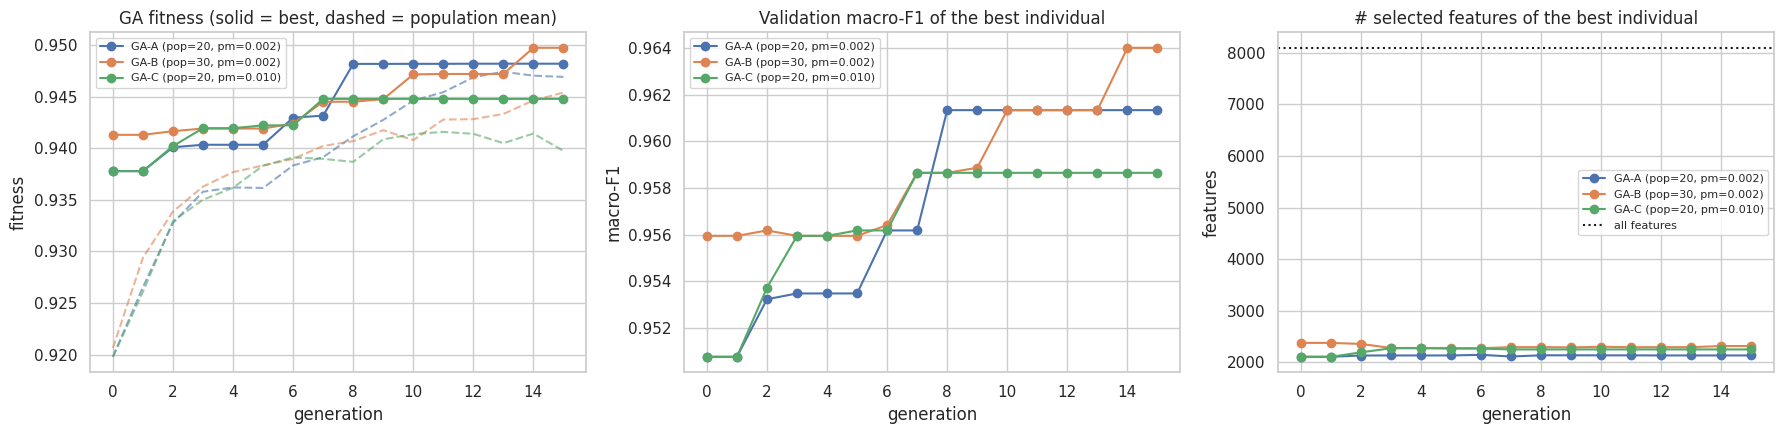

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
for r in ga_runs:
    x = np.arange(len(r["hist"]["best_fit"]))
    l, = axs[0].plot(x, r["hist"]["best_fit"], marker="o", label=r["name"])
    axs[0].plot(x, r["hist"]["mean_fit"], ls="--", color=l.get_color(), alpha=0.6)
    axs[1].plot(x, r["hist"]["best_f1"], marker="o", label=r["name"])
    axs[2].plot(x, r["hist"]["best_k"], marker="o", label=r["name"])
axs[0].set_title("GA fitness (solid = best, dashed = population mean)"); axs[0].set_ylabel("fitness")
axs[1].set_title("Validation macro-F1 of the best individual"); axs[1].set_ylabel("macro-F1")
axs[2].set_title("# selected features of the best individual"); axs[2].axhline(N_FEAT, color="k", ls=":", label="all features"); axs[2].set_ylabel("features")
for a in axs: a.set_xlabel("generation"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ga_fitness.png", dpi=150); plt.show()

## 7. Model selection (validation only) and final GA-HOG + SVM
The GA setting with the highest validation fitness is selected. The SVM is then re-tuned (C, gamma) on the selected features using the validation set and trained on the **full** training set.

In [11]:
best_run = max(ga_runs, key=lambda r: r["best_fit"])
print("Selected GA setting:", best_run["name"], "| features kept:", best_run["best_k"], "of", N_FEAT)
sel_idx = torch.as_tensor(np.flatnonzero(best_run["mask"]), device=DEVICE)

t0 = time.time()
f1_val_ga, C_g, gm_g = tune_svm(sel_idx, G["train"], Y["train"], G["val"], Y["val"])
T_ga_tune = time.time() - t0
t0 = time.time(); ga_model = GpuSVM(C_g, gm_g).fit(G["train"], Y["train"], sel_idx); T_ga_fit = time.time() - t0
t0 = time.time(); pv_ga = ga_model.predict(G["val"]); T_ga_inf_val = time.time() - t0
val_ga = all_metrics(Y["val"], pv_ga)
print(f"Re-tuned: C={C_g}, gamma_mult={gm_g} | fit {T_ga_fit:.1f}s | val inference {T_ga_inf_val:.2f}s")

val_tbl = pd.DataFrame({"HOG + SVM (val)": val_base, "GA-HOG + SVM (val)": val_ga}).round(3)
val_tbl["Δ"] = (val_tbl.iloc[:, 1] - val_tbl.iloc[:, 0]).round(3)
val_tbl

Selected GA setting: GA-B (pop=30, pm=0.002) | features kept: 2312 of 8100
Re-tuned: C=1, gamma_mult=0.5 | fit 1.7s | val inference 0.24s


,HOG + SVM (val),GA-HOG + SVM (val),Δ
Accuracy (%),96.756,97.137,0.381
"Precision (Macro, %)",96.780,96.362,-0.418
"Recall (Macro, %)",94.671,96.137,1.466
Macro-F1 (%),95.663,96.249,0.586
Weighted-F1 (%),96.718,97.134,0.416
Balanced accuracy (%),94.671,96.137,1.466
"Specificity (Macro, %)",94.671,96.137,1.466
Cohen's kappa,0.913,0.925,0.012
Matthews corrcoef,0.914,0.925,0.011


## 8. Final evaluation on the TEST set (used once, after model selection)

In [12]:
t0 = time.time(); pt_base = base.predict(G["test"]);     T_base_inf = time.time() - t0
t0 = time.time(); pt_ga   = ga_model.predict(G["test"]); T_ga_inf   = time.time() - t0
test_base, test_ga = all_metrics(Y["test"], pt_base), all_metrics(Y["test"], pt_ga)

t2 = pd.DataFrame({"HOG + SVM (Baseline)": test_base, "GA-HOG + SVM (Proposed)": test_ga})
t2["Improvement"] = t2.iloc[:, 1] - t2.iloc[:, 0]
t2.index.name = "Metric"
t2.round(3).to_csv(f"{OUT_DIR}/table2_main_comparison.csv")
print("Table 2. Main performance comparison on the TEST set  (Improvement = GA − Baseline; percentage points for % metrics)")
t2.round(3).style.format("{:.3f}").background_gradient(subset=["Improvement"], cmap="RdYlGn", vmin=-5, vmax=5)

Table 2. Main performance comparison on the TEST set  (Improvement = GA − Baseline; percentage points for % metrics)


,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement
Metric,,,
Accuracy (%),81.571,83.814,2.244
"Precision (Macro, %)",88.255,89.106,0.851
"Recall (Macro, %)",75.513,78.590,3.077
Macro-F1 (%),77.364,80.630,3.266
Weighted-F1 (%),79.803,82.593,2.790
Balanced accuracy (%),75.513,78.590,3.077
"Specificity (Macro, %)",75.513,78.590,3.077
Cohen's kappa,0.565,0.623,0.059
Matthews corrcoef,0.625,0.669,0.044


## 9. Computational cost and feature dimensionality

                    Stage (seconds)  HOG + SVM  GA-HOG + SVM
HOG extraction (shared, all splits)      58.50         58.50
               GA feature selection       0.00        273.25
  Hyper-parameter tuning (C, gamma)      18.48          8.00
Final SVM training (full train set)       4.85          1.75
                 Test-set inference       0.86          0.22
                     TOTAL pipeline      82.69        341.72
                 Number of features    8100.00       2312.00
                    Support vectors     947.00        889.00

All GA settings together cost 623s (selected one: 273s).


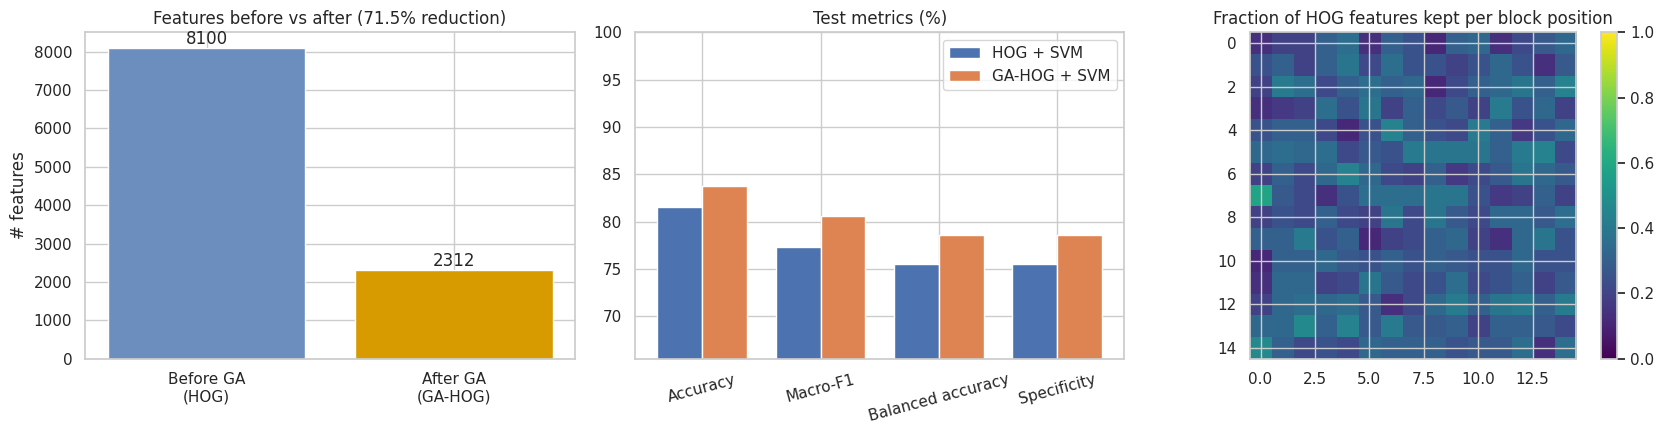

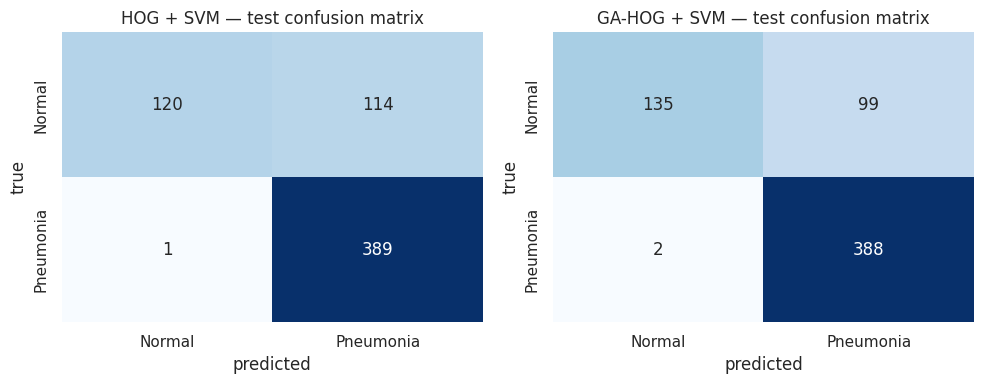

In [13]:
t3 = pd.DataFrame([
    ["HOG extraction (shared, all splits)", T_HOG, T_HOG],
    ["GA feature selection", 0.0, best_run["time"]],
    ["Hyper-parameter tuning (C, gamma)", T_base_tune, T_ga_tune],
    ["Final SVM training (full train set)", T_base_fit, T_ga_fit],
    ["Test-set inference", T_base_inf, T_ga_inf],
], columns=["Stage (seconds)", "HOG + SVM", "GA-HOG + SVM"])
t3.loc[len(t3)] = ["TOTAL pipeline", t3.iloc[:, 1].sum(), t3.iloc[:, 2].sum()]
t3.loc[len(t3)] = ["Number of features", N_FEAT, best_run["best_k"]]
t3.loc[len(t3)] = ["Support vectors", int(base.clf.n_support_.sum()), int(ga_model.clf.n_support_.sum())]
t3.round(2).to_csv(f"{OUT_DIR}/table3_computational_cost.csv", index=False)
print(t3.round(2).to_string(index=False))
print(f"\nAll GA settings together cost {sum(r['time'] for r in ga_runs):.0f}s (selected one: {best_run['time']:.0f}s).")

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
axs[0].bar(["Before GA\n(HOG)", "After GA\n(GA-HOG)"], [N_FEAT, best_run["best_k"]], color=["#6c8ebf", "#d79b00"])
for i, v in enumerate([N_FEAT, best_run["best_k"]]): axs[0].text(i, v, str(v), ha="center", va="bottom")
axs[0].set_title(f"Features before vs after ({100*(1-best_run['best_k']/N_FEAT):.1f}% reduction)"); axs[0].set_ylabel("# features")

mkeys = ["Accuracy (%)", "Macro-F1 (%)", "Balanced accuracy (%)", "Specificity (Macro, %)"]
xx = np.arange(len(mkeys)); w = 0.38
axs[1].bar(xx - w/2, [test_base[k] for k in mkeys], w, label="HOG + SVM"); axs[1].bar(xx + w/2, [test_ga[k] for k in mkeys], w, label="GA-HOG + SVM")
axs[1].set_xticks(xx); axs[1].set_xticklabels([k.replace(" (%)", "").replace(" (Macro, %)", "") for k in mkeys], rotation=15)
axs[1].set_ylim(min(min(test_base[k], test_ga[k]) for k in mkeys) - 10, 100); axs[1].set_title("Test metrics (%)"); axs[1].legend()

# spatial map of kept features: fraction of selected HOG values per 8x8 cell-block position (15x15 blocks)
nb = IMG_SIZE // 8 - 1
m = best_run["mask"].reshape(nb, nb, 2, 2, 9).mean(axis=(2, 3, 4))
im = axs[2].imshow(m, cmap="viridis", vmin=0, vmax=1); axs[2].set_title("Fraction of HOG features kept per block position")
plt.colorbar(im, ax=axs[2]); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/features_and_metrics.png", dpi=150); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for a, (nm, p) in zip(axs, [("HOG + SVM", pt_base), ("GA-HOG + SVM", pt_ga)]):
    sns.heatmap(confusion_matrix(Y["test"], p), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    a.set_title(f"{nm} — test confusion matrix"); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150); plt.show()

### 9.1 Is the difference meaningful? (paired bootstrap on the test set)

In [14]:
rng = np.random.default_rng(SEED); n = len(Y["test"]); diffs = []
for _ in range(2000):
    b = rng.integers(0, n, n)
    diffs.append(100 * (macro_f1(Y["test"][b], pt_ga[b]) - macro_f1(Y["test"][b], pt_base[b])))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Macro-F1 difference (GA − baseline): {np.mean(diffs):+.2f} pp, 95% bootstrap CI [{lo:+.2f}, {hi:+.2f}]")
print("=> CI contains 0: the difference is NOT statistically distinguishable from noise." if lo <= 0 <= hi else
      "=> CI excludes 0: the difference is statistically meaningful.")

Macro-F1 difference (GA − baseline): +3.27 pp, 95% bootstrap CI [+1.44, +5.35]
=> CI excludes 0: the difference is statistically meaningful.


## 10. Results summary and discussion

In [15]:
d = t2["Improvement"]
red = 100 * (1 - best_run["best_k"] / N_FEAT)
print("=== AUTOMATIC SUMMARY OF THE ACTUAL RESULTS (test set) ===")
print(f"* Feature dimensionality: {N_FEAT} -> {best_run['best_k']}  ({red:.1f}% fewer features).")
print(f"* Macro-F1: {test_base['Macro-F1 (%)']:.2f}% -> {test_ga['Macro-F1 (%)']:.2f}%  ({d['Macro-F1 (%)']:+.2f} pp).")
print(f"* Accuracy: {test_base['Accuracy (%)']:.2f}% -> {test_ga['Accuracy (%)']:.2f}%  ({d['Accuracy (%)']:+.2f} pp);  Balanced acc.: {d['Balanced accuracy (%)']:+.2f} pp;  MCC: {d['Matthews corrcoef']:+.3f}.")
print(f"* Cost: GA search took {best_run['time']:.0f}s ({best_run['n_evals']} SVM evaluations) vs. 0s for the baseline; "
      f"final SVM training {T_base_fit:.1f}s -> {T_ga_fit:.1f}s; test inference {T_base_inf:.2f}s -> {T_ga_inf:.2f}s.")
verdict = ("GA-based selection IMPROVED macro-F1 while using fewer features." if d["Macro-F1 (%)"] > 0 and red > 0 else
           "GA-based selection reduced dimensionality with comparable/slightly lower macro-F1 (a trade-off)." if red > 0 and d["Macro-F1 (%)"] > -1 else
           "In this run GA-based selection did NOT improve macro-F1; see limitations below.")
print("* Verdict:", verdict)

=== AUTOMATIC SUMMARY OF THE ACTUAL RESULTS (test set) ===
* Feature dimensionality: 8100 -> 2312  (71.5% fewer features).
* Macro-F1: 77.36% -> 80.63%  (+3.27 pp).
* Accuracy: 81.57% -> 83.81%  (+2.24 pp);  Balanced acc.: +3.08 pp;  MCC: +0.044.
* Cost: GA search took 273s (450 SVM evaluations) vs. 0s for the baseline; final SVM training 4.8s -> 1.7s; test inference 0.86s -> 0.22s.
* Verdict: GA-based selection IMPROVED macro-F1 while using fewer features.


### Discussion (read together with the numbers printed above)

**Strengths**
* **Dimensionality reduction:** the GA directly optimises a trade-off between validation macro-F1 and the number of kept HOG features, so the final classifier is smaller (fewer features → cheaper kernel evaluations and inference, smaller memory footprint).
* **Task-adaptive:** the selected mask shows which spatial regions/orientations of the X-ray are informative (see the block-position map); background/border cells are typically dropped.
* **Classifier-agnostic wrapper:** because the SVM is in the loop, features are chosen for the actual downstream objective (macro-F1) rather than a proxy such as variance.
* **Class-imbalance aware:** macro-F1 as fitness plus balanced class weights prevents the GA from favouring the majority class (Pneumonia).

**Limitations**
* **Computational cost:** every fitness evaluation trains an SVM; the GA needs hundreds of them (see the cost table), so total pipeline time is much higher than the baseline even though the final model is cheaper. We mitigated this with GPU kernels and a training sub-sample inside the GA.
* **Validation over-fitting:** the same validation set drives both the GA and model selection; with a small validation set (~524 images) a mask can fit validation noise. The untouched test set and the bootstrap interval above guard against over-claiming.
* **Stochastic & setting-dependent:** results depend on seed, population size, mutation rate, λ and the number of generations; one seed was used here, so small differences should be treated with caution. A binary 8100-bit search space is large relative to 15–30 individuals × 15 generations.
* **Low native resolution:** PneumoniaMNIST images are 28×28 (up-sampled to 128×128), so HOG captures interpolated gradients; HOG itself is a hand-crafted descriptor and typically lags CNNs on this task.

**Computational cost summary:** GA cost ≈ (#evaluations) × (cost of one SVM fit on the sub-sample + validation prediction). Inference cost scales with the number of kept features and support vectors, which is why the proposed model is cheaper at prediction time but more expensive to *build*.

**Answer to the research question:** see the automatic verdict above — it is derived from the actual test-set numbers of this run, and the bootstrap CI tells you whether any gain is statistically meaningful.

## 11. Save artefacts

In [16]:
np.save(f"{OUT_DIR}/selected_feature_mask.npy", best_run["mask"])
pd.DataFrame({"fitness_best": best_run["hist"]["best_fit"], "fitness_mean": best_run["hist"]["mean_fit"],
              "best_val_f1": best_run["hist"]["best_f1"], "best_k": best_run["hist"]["best_k"]}).to_csv(f"{OUT_DIR}/ga_history_selected.csv", index_label="generation")
print("Saved to", OUT_DIR, ":", os.listdir(OUT_DIR))
# Optional: download everything as a zip
# !cd /content && zip -qr lab07_outputs.zip lab07_outputs
# from google.colab import files; files.download("/content/lab07_outputs.zip")

Saved to /content/lab07_outputs : ['table2_main_comparison.csv', 'features_and_metrics.png', 'ga_history_selected.csv', 'table3_computational_cost.csv', 'samples.png', 'table1_config.csv', 'selected_feature_mask.npy', 'ga_fitness.png', 'table_ga_settings.csv', 'confusion_matrices.png']


In [17]:
import shutil
from google.colab import files

shutil.make_archive("/content/lab07_outputs", "zip", "/content/lab07_outputs")
files.download("/content/lab07_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>